# Откривање аномалии со Махаланобисова дистанца

Махаланобисова дистанца според името е токму тоа, статистичка мерка за дистанца која мери колку стандардни девиации една точка е од средната вредност(mean) со оглед на формата(covariance) на податоците.

<center><img src="../images/mahalanobis_2d_graph.webp"></center>

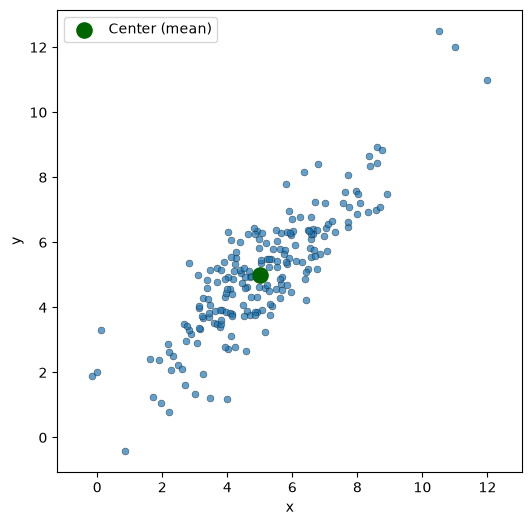

In [31]:
import numpy as np
import matplotlib.pyplot as plt
"""
    2D Dataset for Mahalanobis Distance 
"""



rng = np.random.default_rng(42)

mean = np.array([5.0, 5.0])
cov  = np.array([[3.0, 2.4],
                 [2.4, 3.0]])   

n = 200
outliers = np.array([[11, 12], [12, 11], [10.5, 12.5], [0, 2]])
X = rng.multivariate_normal(mean, cov, size=n)
X_2d = np.vstack([X, outliers])

plt.figure(figsize=(6, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=25, alpha=0.7, edgecolors='k', linewidths=0.3)
plt.scatter(*mean, color='darkgreen', s=120, zorder=5, label='Center (mean)')
plt.xlabel('x'); plt.ylabel('y')
plt.axis('equal')
plt.legend()
plt.show()

## Лаб 2: Испитај редундантни карактеристики и ранг на коваријациска матрица

In [9]:
print(X_2d.shape)

(204, 2)


In [36]:
"""
    Матрица на корелација која покажува дека x1 и x3 се редундантни)
    
    x3 = 2 * X_2d[:, 0] - линеарна функција која ја прави x3 редундантна во однос на x1.
"""



x3 = 2 * X_2d[:, 0]
X_redundant = np.column_stack([X_2d, x3])     

print(X_redundant.shape)

print("Матрица на Корелација:")
print(np.corrcoef(X_redundant, rowvar=False))

print("Матрица на Коваријанца:")
Covariance_matrix = np.cov(X_redundant, rowvar=False)
print(Covariance_matrix)

print("Ранг:")
rank = np.linalg.matrix_rank(Covariance_matrix)
print(rank)

(204, 3)
Матрица на Корелација:
[[1.         0.85399666 1.        ]
 [0.85399666 1.         0.85399666]
 [1.         0.85399666 1.        ]]
Матрица на Коваријанца:
[[ 3.61986995  3.03085019  7.23973989]
 [ 3.03085019  3.47955441  6.06170037]
 [ 7.23973989  6.06170037 14.47947979]]
Ранг:
2


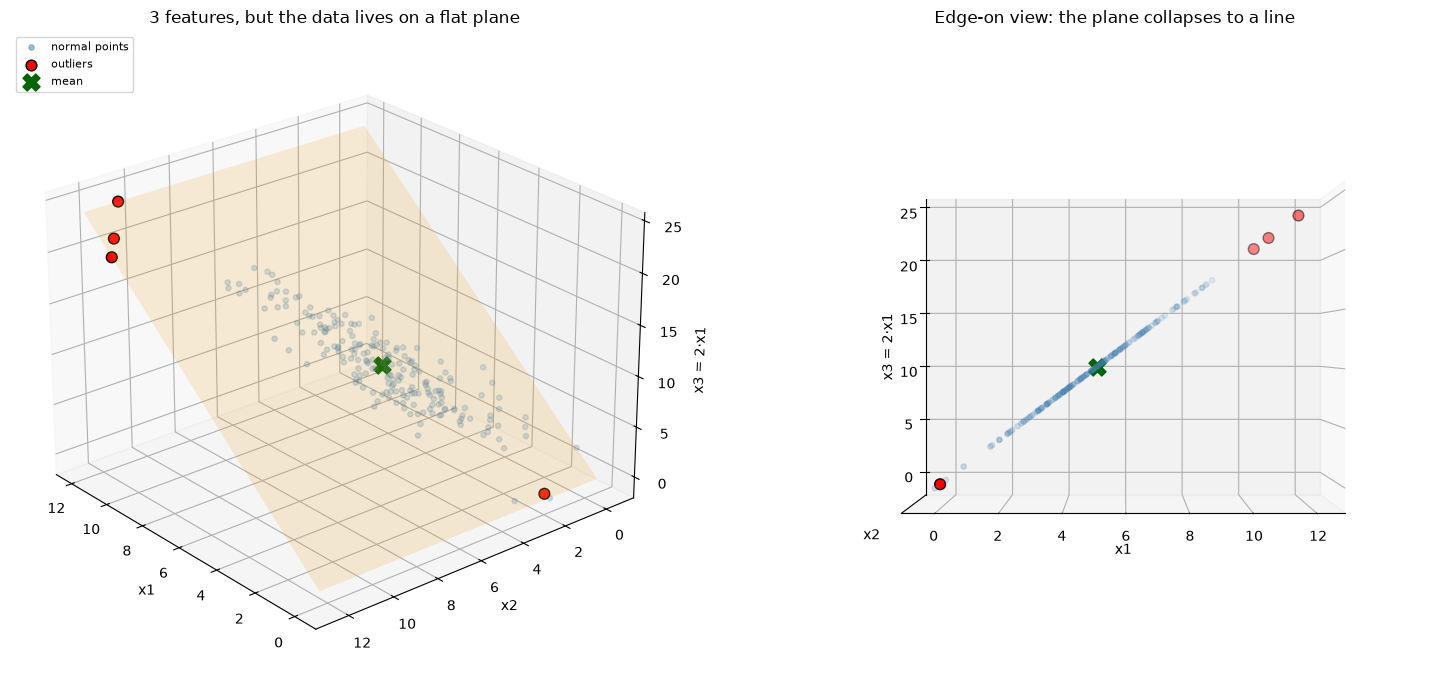

In [40]:
def plot_redundant_3d(M, elev=20, azim=-60, ax=None, title="", n_out=4):
    mu = M.mean(axis=0)
    C = np.cov(M, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(C)          # ascending order
    if ax is None:
        fig = plt.figure(figsize=(8, 7))
        ax = fig.add_subplot(111, projection="3d")

    ax.scatter(*M[:-n_out].T, s=14, alpha=0.5, color="steelblue", label="normal points")
    ax.scatter(*M[-n_out:].T, s=60, color="red", edgecolor="k", label="outliers")
    ax.scatter(*mu, s=150, color="darkgreen", marker="X", label="mean")

    # the plane x3 = 2*x1 that all the data lives on
    gx, gy = np.meshgrid(np.linspace(M[:, 0].min(), M[:, 0].max(), 10),
                         np.linspace(M[:, 1].min(), M[:, 1].max(), 10))
    ax.plot_surface(gx, gy, 2 * gx, alpha=0.15, color="orange", linewidth=0)

    # eigenvector arrows from the mean (length = 2 std; the null one gets a fixed length so it's visible)
    colors = ["black", "navy", "crimson"]
    names = ["null direction", "minor axis", "major axis"]
    

    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("x3 = 2·x1")
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(title)
    return ax

fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(121, projection="3d")
plot_redundant_3d(X_redundant, elev=25, azim=140, ax=ax1,
                  title="3 features, but the data lives on a flat plane")
ax1.legend(loc="upper left", fontsize=8)

ax2 = fig.add_subplot(122, projection="3d")
plot_redundant_3d(X_redundant, elev=0, azim=-90, ax=ax2,
                  title="Edge-on view: the plane collapses to a line")
ax2.set_yticks([])
plt.tight_layout()
plt.show()